In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import numpy as np
import xarray as xr
import cftime
import pandas as pd
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import LinearSegmentedColormap, BoundaryNorm
from matplotlib.patches import Rectangle, Ellipse
import matplotlib.colors as mcolors
import cmaps
import inspect
from mpl_toolkits.axes_grid1 import make_axes_locatable
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter

plt.rcParams['font.family'] = 'serif'         
plt.rcParams['font.serif'] = ['Times New Roman']

In [4]:
alh = 'abcdefghijklmno'

In [5]:
def plot_sst(axs, data, levels, draw_title=False, draw_text=False, cmap=cmaps.hotcold_18lev):
    for i, ax in enumerate(axs.flatten()):
        ax.set_aspect('auto')
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2) 
            spine.set_edgecolor('black')
        ax.set_extent([-180, 180, -40, 40], crs=ccrs.PlateCarree(central_longitude=180))
        ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='#F5F5F5', lw=0.1, zorder=1)
        ax.coastlines(lw=0.6, color='k')
        major_lon = np.array([0, 60, 120, 180, 240, 300, 360])
        major_lat = [-40,-20, 0, 20, 40]
        minor_lon = range(0, 331, 30) 
        minor_lat = range(-40, 41, 10)
        ax.set_xticks(major_lon-180, crs=ccrs.PlateCarree(central_longitude=180)) 
        ax.set_xticks(minor_lon, crs=ccrs.PlateCarree(), minor=True)
        ax.set_yticks(major_lat, crs=ccrs.PlateCarree())
        ax.set_yticks(minor_lat, crs=ccrs.PlateCarree(), minor=True)
        ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
        ax.yaxis.set_major_formatter(LatitudeFormatter())
        ax.tick_params(axis='both', which='major', direction='out',
                    length=5, width=1.2, labelsize=9, colors='black')
        ax.tick_params(axis='both', which='minor', direction='out',
                    length=2, width=1, colors='black')
        ax.tick_params(axis='both', labelsize=9)
        if draw_title:
            ax.set_title(titles[i], fontsize=12)
        if draw_text:
            ax.text(-0.02, 1.05, texts[i], transform=ax.transAxes, fontsize=16, fontweight='bold')
        cb = ax.contourf(lon, lat, data[i], levels=levels, cmap=cmap, transform=ccrs.PlateCarree(), extend='both')
        # LAT, LON = np.meshgrid(lat, lon, indexing='ij')
        # mask = pvalue[i] <= 0.05
        # skip = 4
        # ax.scatter(LON[mask][::skip, ::skip], LAT[mask][::skip, ::skip], color='k', s=2, transform=ccrs.PlateCarree())
    return cb

def plot_TC(axs, data1, data2, level1, level2, draw_title=False, draw_text=False):
    for i, ax in enumerate(axs.flatten()):
        ax.set_aspect('auto')
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2) 
            spine.set_edgecolor('black')
        ax.set_extent([-180, 180, -40, 40], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.LAND.with_scale('50m'), facecolor='#F5F5F5', lw=0.1, zorder=1)
        ax.coastlines(lw=0.6, color='k')
        major_lon = [0, 60, 120, 180, 240, 300, 360]
        major_lat = [-40,-20, 0, 20, 40]
        minor_lon = range(0, 361, 30) 
        minor_lat = range(-40, 41, 10)
        ax.set_xticks(major_lon, crs=ccrs.PlateCarree()) 
        ax.set_xticks(minor_lon, crs=ccrs.PlateCarree(), minor=True)
        ax.set_yticks(major_lat, crs=ccrs.PlateCarree())
        ax.set_yticks(minor_lat, crs=ccrs.PlateCarree(), minor=True)
        ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
        ax.yaxis.set_major_formatter(LatitudeFormatter())
        ax.tick_params(axis='both', which='major', direction='out',
                    length=5, width=1.2, labelsize=9, colors='black')
        ax.tick_params(axis='both', which='minor', direction='out',
                    length=2, width=1, colors='black')
        ax.tick_params(axis='both', labelsize=9)
        if draw_title:
            ax.set_title(titles[i], fontsize=12)
        if draw_text:
            ax.text(-0.02, 1.05, texts[i], transform=ax.transAxes, fontsize=16, fontweight='bold')
        cb = ax.contourf(lon, lat, data1[i], levels=level1, cmap=cmaps.hotcold_18lev, transform=ccrs.PlateCarree(), extend='both')
        ax.contour(lon, lat, data2[i], levels=level2[level2>0], colors='purple', linewidths=1.6, linestyles='solid', transform=ccrs.PlateCarree())
        ax.contour(lon, lat, data2[i], levels=level2[level2<0], colors='blue', linewidths=1.6, linestyles='solid', transform=ccrs.PlateCarree())
        # LAT, LON = np.meshgrid(lat, lon, indexing='ij')
        # mask = pvalue[i] <= 0.05
        # skip = 4
        # ax.scatter(LON[mask][::skip, ::skip], LAT[mask][::skip, ::skip], color='k', s=2, transform=ccrs.PlateCarree())
    return cb

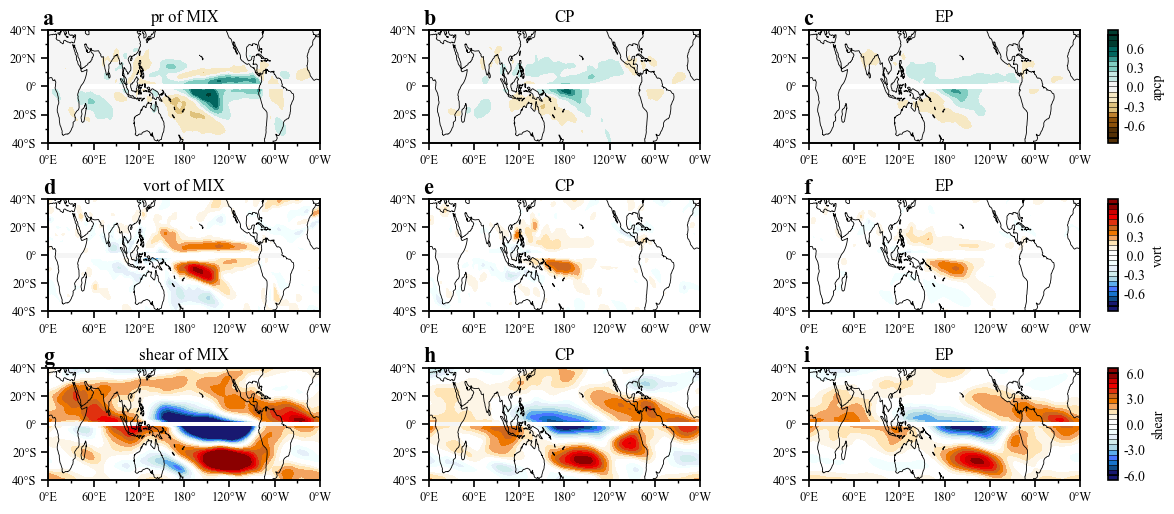

In [11]:
fig, axs = plt.subplots(3, 3, figsize=(12, 5), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})


ds_nino = xr.open_dataset('./data-20c/composite_kde.nc')
lon = ds_nino.lon.values
lat = ds_nino.lat.values

Ntc_start, Ntc_end = 5, 10
Stc_start, Stc_end = 11, 16

Ntcg_grid = ds_nino.apcp.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stcg_grid = ds_nino.apcp.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()

tcg_grid.loc[:, -1:1, :] = np.nan
level_apcp = np.linspace(-0.8, 0.8, 21)
titles = ['pr of MIX', 'CP', 'EP', 'SUC']
texts = alh[:3]
cb = plot_sst(axs[0, :], tcg_grid, level_apcp, draw_title=True, draw_text=True, cmap=cmaps.CBR_drywet)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[0, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[0, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-0.6, -0.3, 0, 0.3, 0.6])
cbar.ax.set_ylabel('apcp')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

Ntcg_grid = ds_nino.vort.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stcg_grid = -ds_nino.vort.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()

tcg_grid.loc[:, -1:1, :] = np.nan
level_vort = np.linspace(-0.8, 0.8, 21)
titles = ['vort of MIX', 'CP', 'EP', 'SUC']
texts = alh[3:6]
cb = plot_sst(axs[1, :], tcg_grid*1e+5, level_vort, draw_title=True, draw_text=True)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[1, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[1, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-0.6, -0.3, 0, 0.3, 0.6])
cbar.ax.set_ylabel('vort')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

dVdz = ds_nino.uwnd.loc[:, :, 200] - ds_nino.uwnd.loc[:, :, 850]
Ntcg_grid = dVdz.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stcg_grid = dVdz.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()

tcg_grid.loc[:, -1:1, :] = np.nan
level_shear = np.linspace(-6, 6, 21)
titles = ['shear of MIX', 'CP', 'EP', 'SUC']
texts = alh[6:9]
cb = plot_sst(axs[2, :], tcg_grid, level_shear, draw_title=True, draw_text=True)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[2, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[2, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-6, -3, 0, 3, 6])
cbar.ax.set_ylabel('shear')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')




fig.subplots_adjust(left=0.07, right=0.93, bottom=0.05, top=0.95, wspace=0.4, hspace=0.5)
fig.savefig('./pic-20c/vort shear summer.png')

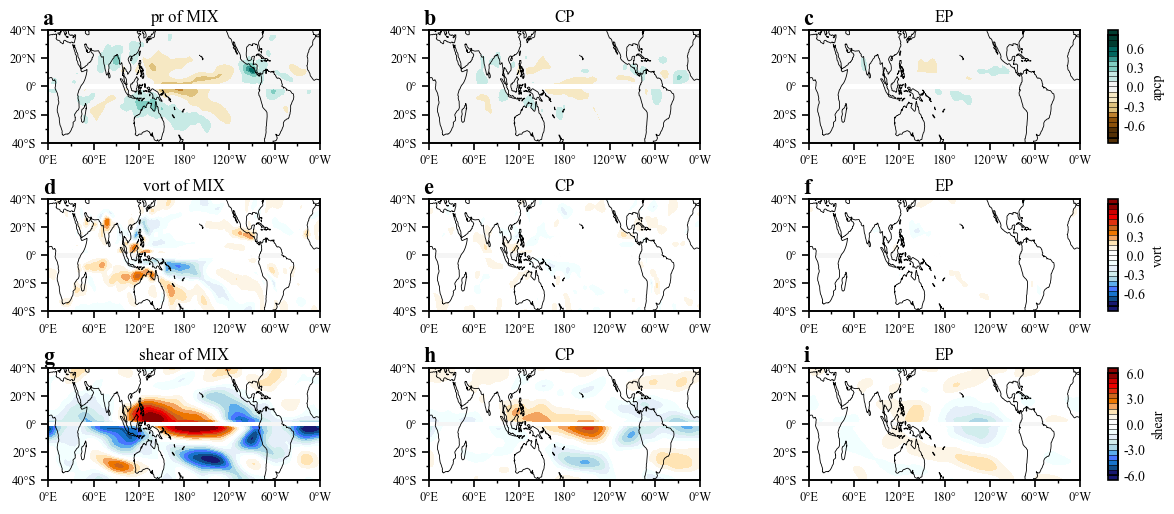

In [12]:
fig, axs = plt.subplots(3, 3, figsize=(12, 5), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})


ds_nino = xr.open_dataset('./data-20c/composite_kde.nc')
lon = ds_nino.lon.values
lat = ds_nino.lat.values

Ntc_start, Ntc_end = 5+12, 10+12
Stc_start, Stc_end = 11+12, 16+12

Ntcg_grid = ds_nino.apcp.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stcg_grid = ds_nino.apcp.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()

tcg_grid.loc[:, -1:1, :] = np.nan
level_apcp = np.linspace(-0.8, 0.8, 21)
titles = ['pr of MIX', 'CP', 'EP', 'SUC']
texts = alh[:3]
cb = plot_sst(axs[0, :], tcg_grid, level_apcp, draw_title=True, draw_text=True, cmap=cmaps.CBR_drywet)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[0, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[0, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-0.6, -0.3, 0, 0.3, 0.6])
cbar.ax.set_ylabel('apcp')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

Ntcg_grid = ds_nino.vort.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stcg_grid = -ds_nino.vort.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()

tcg_grid.loc[:, -1:1, :] = np.nan
level_vort = np.linspace(-0.8, 0.8, 21)
titles = ['vort of MIX', 'CP', 'EP', 'SUC']
texts = alh[3:6]
cb = plot_sst(axs[1, :], tcg_grid*1e+5, level_vort, draw_title=True, draw_text=True)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[1, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[1, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-0.6, -0.3, 0, 0.3, 0.6])
cbar.ax.set_ylabel('vort')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

dVdz = ds_nino.uwnd.loc[:, :, 200] - ds_nino.uwnd.loc[:, :, 850]
Ntcg_grid = dVdz.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stcg_grid = dVdz.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()

tcg_grid.loc[:, -1:1, :] = np.nan
level_shear = np.linspace(-6, 6, 21)
titles = ['shear of MIX', 'CP', 'EP', 'SUC']
texts = alh[6:9]
cb = plot_sst(axs[2, :], tcg_grid, level_shear, draw_title=True, draw_text=True)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[2, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[2, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-6, -3, 0, 3, 6])
cbar.ax.set_ylabel('shear')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')




fig.subplots_adjust(left=0.07, right=0.93, bottom=0.05, top=0.95, wspace=0.4, hspace=0.5)
fig.savefig('./pic-20c/vort shear next year.png')

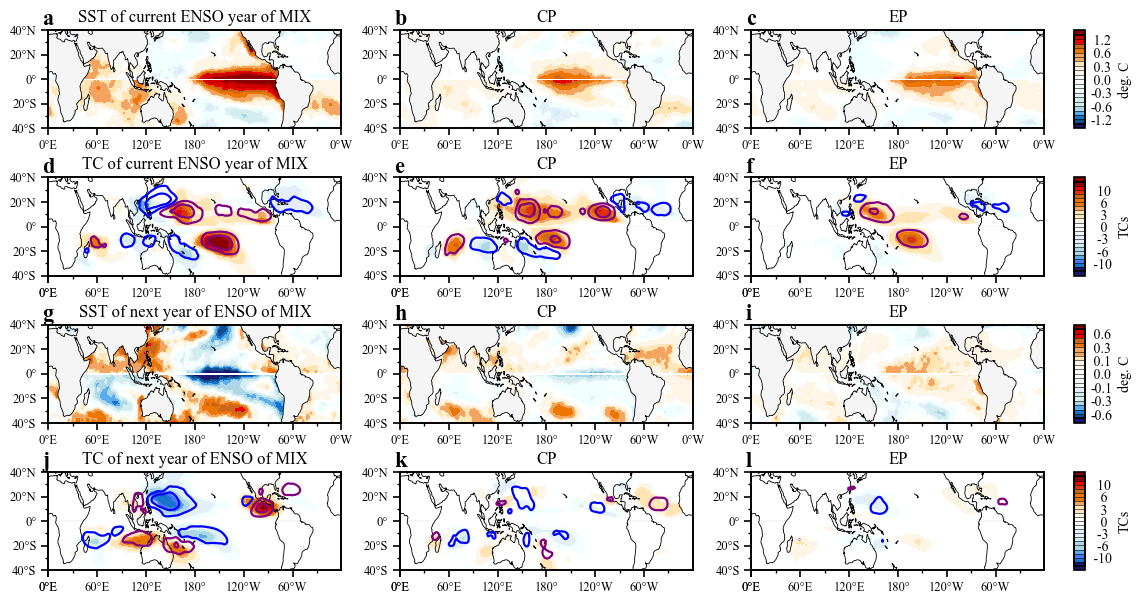

In [6]:
nrows, ncols = 4, 3
wsize, hsize = 12, 6
fig, axs = plt.subplots(nrows, ncols, figsize=(wsize, hsize), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

ds_nino = xr.open_dataset('./data-20c/composite_tc_sst.nc')
# ds_nino = xr.open_dataset('./data-d4pdf/composite_tc_sst.nc')
# ds_nino_obs = xr.open_dataset('./data-20c/composite_tc_sst_obs.nc')
sst_start, sst_end = 11, 13
Ntc_start, Ntc_end = 5, 10
Stc_start, Stc_end = 11, 16

# sst_grid = ds_nino.sst.loc[:, sst_start:sst_end, -40:40, :].mean(axis=1)
Nsst_grid = ds_nino.sst.loc[:, Ntc_start:Ntc_end, -0:40, :].mean(axis=1)
Ssst_grid = ds_nino.sst.loc[:, Stc_start:Stc_end, -40:0, :].mean(axis=1)
sst_grid = xr.concat([Ssst_grid, Nsst_grid], dim='lat')
Ntcg_grid = ds_nino.tcg.loc[:, Ntc_start:Ntc_end, 0:40, :].sum(axis=1)
Stcg_grid = ds_nino.tcg.loc[:, Stc_start:Stc_end, -40:-1, :].sum(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()
Ntct_grid = ds_nino.tct.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stct_grid = ds_nino.tct.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tct_grid = xr.concat([Stct_grid, Ntct_grid], dim='lat')

sst_grid.loc[:, 0, :] = np.nan
tcg_grid.loc[:, 0, :] = np.nan
tct_grid.loc[:, 0, :] = np.nan

# titles = ['D(0)JF SST of MIX', 'CP', 'EP', 'SUC']
titles = ['SST of current ENSO year of MIX', 'CP', 'EP', '']
texts = alh[:3]
lon = sst_grid.lon.values
lat = sst_grid.lat.values

levels = np.array([-1.6, -1.2, -1, -0.8, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1])
level_sst = np.r_[levels, 0, -levels[::-1]]
# level_sst = np.arange(-1.2, 1.21, 0.2)
# levels = np.array([-2.5, -2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, -0.1])
# level_tcg = np.r_[levels, 0, -levels[::-1]]
level_tcg = np.array([-1.3, -0.4, 0.4, 1.3])
levels = np.array([-14, -12, -10, -8, -7, -6, -5, -4, -3, -2, -1])
level_tct = np.r_[levels, 0, -levels[::-1]]

nax = 0
cb = plot_sst(axs[nax, :], sst_grid, level_sst, draw_title=True, draw_text=True)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[nax, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[nax, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
# cbar.ax.set_yticks([-1.2, -0.4, 0, 0.4, 1.2])
cbar.ax.set_ylabel('deg. C')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')



nax = 1
titles = ['TC of current ENSO year of MIX', 'CP', 'EP', '']
texts = alh[3:6]
lon = tcg_grid.lon.values
lat = tcg_grid.lat.values
cb = plot_TC(axs[nax, :], tct_grid, tcg_grid, level_tct, level_tcg, draw_title=True, draw_text=True)
cax = inset_axes(axs[nax, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[nax, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.0f', cax=cax)
cbar.ax.tick_params(length=0)
# cbar.ax.set_yticks([-10, -5, 0, 5, 10])
cbar.ax.set_ylabel('TCs')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')


# ----------- Sourth -------------
levels = np.array([-1.6, -1.2, -1, -0.8, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1])
level_sst = np.r_[levels, 0, -levels[::-1]] / 2

sst_start, sst_end = 17, 21
Ntc_start, Ntc_end = 5+12, 10+12
Stc_start, Stc_end = 11+12, 16+12

Nsst_grid = ds_nino.sst.loc[:, Ntc_start:Ntc_end, -0:40, :].mean(axis=1)
Ssst_grid = ds_nino.sst.loc[:, Stc_start:Stc_end, -40:0, :].mean(axis=1)
sst_grid = xr.concat([Ssst_grid, Nsst_grid], dim='lat')
Ntcg_grid = ds_nino.tcg.loc[:, Ntc_start:Ntc_end, 0:40, :].sum(axis=1)
Stcg_grid = ds_nino.tcg.loc[:, Stc_start:Stc_end, -40:-1, :].sum(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()
Ntct_grid = ds_nino.tct.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stct_grid = ds_nino.tct.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tct_grid = xr.concat([Stct_grid, Ntct_grid], dim='lat')

sst_grid.loc[:, 0, :] = np.nan
tcg_grid.loc[:, 0, :] = np.nan
tct_grid.loc[:, 0, :] = np.nan


nax = 2
# titles = ['JJAS SST of MIX of MIX', 'CP', 'EP', 'SUC']
titles = ['SST of next year of ENSO of MIX', 'CP', 'EP', '']
texts = alh[6:9]
lon = sst_grid.lon.values
lat = sst_grid.lat.values
cb = plot_sst(axs[nax, :], sst_grid, level_sst, draw_title=True, draw_text=True)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[nax, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[nax, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
# cbar.ax.set_yticks([-0.6, -0.3, 0, 0.3, 0.6])
cbar.ax.set_ylabel('deg. C')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')



nax = 3
titles = ['TC of next year of ENSO of MIX', 'CP', 'EP', '']
texts = alh[9:12]
lon = tcg_grid.lon.values
lat = tcg_grid.lat.values
cb = plot_TC(axs[nax, :], tct_grid, tcg_grid, level_tct, level_tcg, draw_title=True, draw_text=True)
cax = inset_axes(axs[nax, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[nax, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.0f', cax=cax)
cbar.ax.tick_params(length=0)
# cbar.ax.set_yticks([-10, -5, 0, 5, 10])
cbar.ax.set_ylabel('TCs')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

# # for ax in axs[1:, :].flatten():
# #     ax.plot([0, 360], [0, 0], transform=ccrs.PlateCarree(), color='white', linestyle='-', linewidth=2)

fig.subplots_adjust(left=0.07, right=0.9, bottom=0.05, top=0.95, wspace=0.2, hspace=0.5) 
# fig.savefig('./pic-20c/composite sst TCT lat lon.png', dpi=300)
# fig.savefig('./pic-d4pdf/composite sst TCT lat lon.png', dpi=300)

In [17]:
0.84/(3+2*0.4)*12

2.6526315789473682

In [65]:
get_h(0.4)

0.36309523809523786

In [59]:
get_h = lambda wspace: ((3 * (ncols+(ncols-1)*wspace)/wsize*hsize * 0.9/0.84) - nrows)/(nrows-1)

In [56]:
0.86/(3.8)*12

2.7157894736842105

In [53]:
0.9 / (4+3*0.4) *7

1.2115384615384615

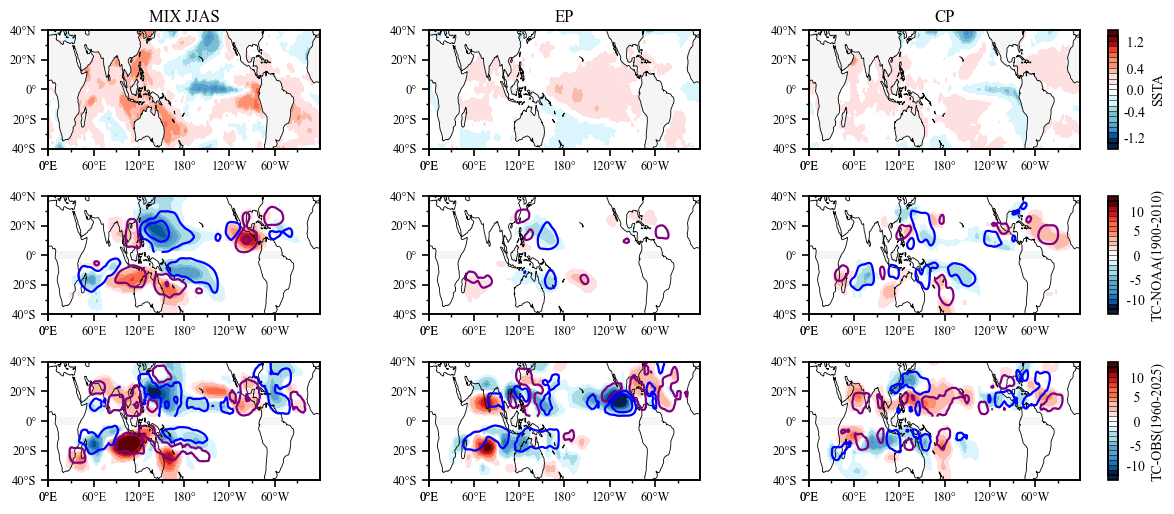

In [42]:
fig, axs = plt.subplots(3, 3, figsize=(12, 5), subplot_kw={'projection': ccrs.PlateCarree(central_longitude=180)})

ds_nino = xr.open_dataset('./data-20c/composite_tc_sst.nc')
ds_nino_obs = xr.open_dataset('./data-20c/composite_tc_sst_obs.nc')
sst_start, sst_end = 17, 21
Ntc_start, Ntc_end = 5+12, 10+12
Stc_start, Stc_end = 11+12, 16+12

sst_grid = ds_nino.sst.loc[:, sst_start:sst_end, -40:40, :].mean(axis=1)
Ntcg_grid = ds_nino.tcg.loc[:, Ntc_start:Ntc_end, 0:40, :].sum(axis=1)
Stcg_grid = ds_nino.tcg.loc[:, Stc_start:Stc_end, -40:-1, :].sum(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()
Ntct_grid = ds_nino.tct.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stct_grid = ds_nino.tct.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tct_grid = xr.concat([Stct_grid, Ntct_grid], dim='lat')

tcg_grid.loc[:, -2:2, :] = np.nan
tct_grid.loc[:, -2:2, :] = np.nan

# sst_p = ds_nino.sst_p.loc[:, start:end, -40:40, :].mean(axis=1)
# tcg_p = ds_nino.tcg_p.loc[:, start:end, -40:40, :].mean(axis=1)
# tct_p = ds_nino.tct_p.loc[:, start:end, -40:40, :].mean(axis=1)

titles = ['MIX JJAS', 'EP', 'CP', 'SUC']
lon = sst_grid.lon.values
lat = sst_grid.lat.values

levels = np.array([-1.6, -1.2, -1, -0.8, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1])
level_sst = np.r_[levels, 0, -levels[::-1]]
# level_sst = np.arange(-1.2, 1.21, 0.2)
# levels = np.array([-2.5, -2, -1.75, -1.5, -1.25, -1, -0.75, -0.5, -0.25, -0.1])
# level_tcg = np.r_[levels, 0, -levels[::-1]]
level_tcg = np.array([-1.3, -0.25, 0.25, 1.3])
levels = np.array([-14, -12, -10, -8, -7, -6, -5, -4, -3, -2, -1])
level_tct = np.r_[levels, 0, -levels[::-1]]

cb = plot_sst(axs[0, :], sst_grid, level_sst, draw_title=True)
# cbaxes = fig.add_axes([0.2, 0.6, 0.6, 0.02])
cax = inset_axes(axs[0, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[0, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-1.2, -0.4, 0, 0.4, 1.2])
cbar.ax.set_ylabel('SSTA')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

cb = plot_TC(axs[1, :], tct_grid, tcg_grid.rolling(lat=3, lon=3, min_periods=1, center=True).mean(), level_tct, level_tcg)
cax = inset_axes(axs[1, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0.0, 1, 1), bbox_transform=axs[1, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.0f', cax=cax)
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-10, -5, 0, 5, 10])
cbar.ax.set_ylabel('TC-NOAA(1900-2010)')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

sst_grid = ds_nino_obs.sst.loc[:, sst_start:sst_end, -40:40, :].mean(axis=1)
Ntcg_grid = ds_nino_obs.tcg.loc[:, Ntc_start:Ntc_end, 0:40, :].sum(axis=1)
Stcg_grid = ds_nino_obs.tcg.loc[:, Stc_start:Stc_end, -40:-1, :].sum(axis=1)
tcg_grid = xr.concat([Stcg_grid, Ntcg_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()
Ntct_grid = ds_nino_obs.tct.loc[:, Ntc_start:Ntc_end, 0:40, :].mean(axis=1)
Stct_grid = ds_nino_obs.tct.loc[:, Stc_start:Stc_end, -40:-1, :].mean(axis=1)
tct_grid = xr.concat([Stct_grid, Ntct_grid], dim='lat').rolling(lat=6, lon=6, min_periods=1, center=True).mean()

tcg_grid.loc[:, -2:2, :] = np.nan
tct_grid.loc[:, -2:2, :] = np.nan
cb = plot_TC(axs[2, :], tct_grid, tcg_grid, level_tct, level_tcg)
cax = inset_axes(axs[2, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0, 1, 1), bbox_transform=axs[2, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.0f', cax=cax)
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-10, -5, 0, 5, 10])
cbar.ax.set_ylabel('TC-OBS(1960-2025)')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

# for ax in axs[1:, :].flatten():
#     ax.plot([0, 360], [0, 0], transform=ccrs.PlateCarree(), color='white', linestyle='-', linewidth=2)

fig.subplots_adjust(left=0.07, right=0.93, bottom=0.05, top=0.95, wspace=0.4, hspace=0.4) 
# fig.savefig('./pic-20c/decrease year.png', dpi=300)
# fig.savefig('./pic-20c/develop year.png', dpi=300)

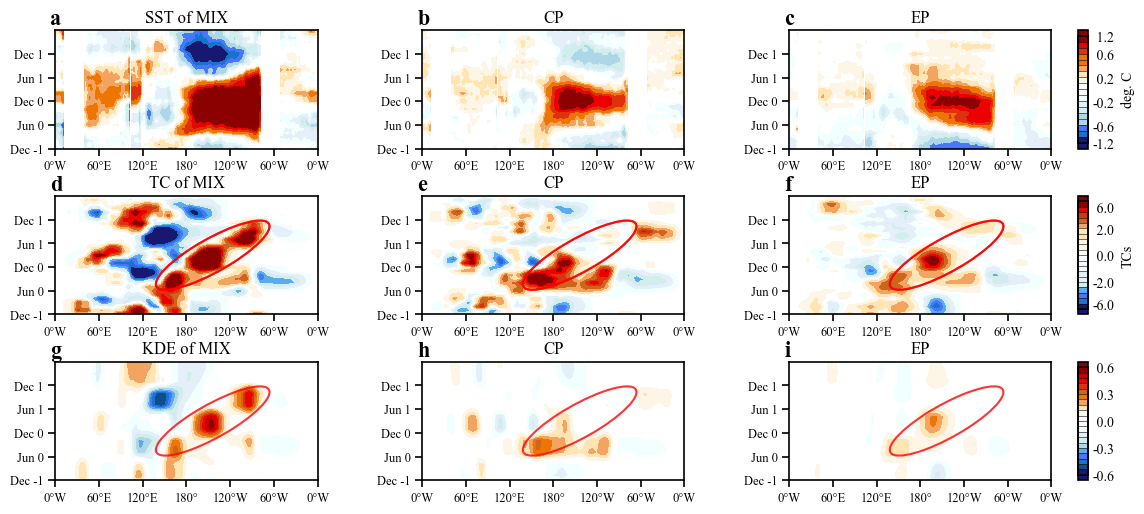

In [8]:
def plot_sst(axs, data, levels, draw_title=False, draw_text=False):
    for i, ax in enumerate(axs.flatten()):
        ax.set_aspect('auto')
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2) 
            spine.set_edgecolor('black')
        if draw_title:
            ax.set_title(titles[i], fontsize=12)
        if draw_text:
            ax.text(-0.02, 1.05, texts[i], transform=ax.transAxes, fontsize=16, fontweight='bold')
        try:
            cb = ax.contourf(lon, mon[5:], data[i, 5:], levels=levels, cmap=cmaps.hotcold_18lev, extend='both')
        except:
            cb = ax.contourf(lon[:-1], mon[5:], data[i, 5:], levels=levels, cmap=cmaps.hotcold_18lev, extend='both')
        ytick = np.array([-1, 5, 11, 17, 23])
        ax.set_yticks(ytick)
        ax.set_yticklabels(months_str[ytick+6], fontsize=8) 
        ax.set_xticks(np.arange(0, 361, 60))
        ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
        ax.tick_params(axis='both', which='major', direction='out', length=5, width=1.2, labelsize=9, colors='black')
    return cb


ds_kde = xr.open_dataset('./data-20c/composite_kde.nc')
ds_nino = xr.open_dataset('./data-20c/composite_tc_sst.nc')
fig, axs = plt.subplots(3, 3, figsize=(12, 5))
mon = ds_nino.month.values
sum_mon = np.r_[mon[0:5], mon[11:17], mon[23:29]]
win_mon = np.r_[mon[5:11], mon[17:23], mon[29: ]]
sst_grid = ds_nino.sst.loc[:, :, -5:5, :].mean(axis=2)
Ntcg_grid = ds_kde.kde.loc[:, sum_mon, 5:25, :].mean(axis=2)
Stcg_grid = ds_kde.kde.loc[:, win_mon, -25:-5, :].mean(axis=2)
tcg_grid = ds_kde.kde.loc[:, :, 0, :].copy()
tcg_grid.loc[:, sum_mon] = Ntcg_grid
tcg_grid.loc[:, win_mon] = Stcg_grid


Ntct_grid = ds_nino.tct.loc[:, sum_mon, 5:25, :].mean(axis=2)
Stct_grid = ds_nino.tct.loc[:, win_mon, -25:-5, :].mean(axis=2)
tct_grid = ds_nino.tct.loc[:, :, 0, :].copy()
tct_grid.loc[:, sum_mon] = Ntct_grid
tct_grid.loc[:, win_mon] = Stct_grid




months_str = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
months_str = np.array([f'{months_str[mon[i]]} -1' for i in range(6)] + [f'{months_str[mon[i]]} 0' for i in range(6, 18)] + [f'{months_str[mon[i]-12]} 1' for i in range(18, 30)] + [f'{months_str[mon[i]-24]} 2' for i in range(30, 36)])
lon = sst_grid.lon.values

levels = np.array([-1.2, -1, -0.8, -0.6, -0.5, -0.4, -0.3, -0.2, -0.1])
level_sst = np.r_[levels, 0, -levels[::-1]]
# level_sst = np.arange(-1.2, 1.21, 0.2)
# levels = np.array([-0.5, -0.4, -0.3, -0.2, -0.1, -0.05])
# level_tcg = np.r_[levels, 0, -levels[::-1]]
level_tcg = np.linspace(-0.6, 0.6, 21)
levels = np.array([-7, -6, -5, -4, -3, -2, -1.5, -1, -0.5, -0.25,])
level_tct = np.r_[levels, 0, -levels[::-1]]

titles = ['SST of MIX', 'CP', 'EP', 'SUC']
texts = alh[:3]
cb = plot_sst(axs[0, :], sst_grid, level_sst, draw_title=True, draw_text=True)
# for ax in axs[0, :].flatten():
#     rect = plt.Rectangle((0, 11), 360, 3, facecolor='gray', alpha=0.4)
#     ax.add_patch(rect)
#     rect = plt.Rectangle((0, 17), 360, 4, facecolor='gray', alpha=0.4)
#     ax.add_patch(rect)
cax = inset_axes(axs[0, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0, 1, 1), bbox_transform=axs[0, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
# cbar.ax.xaxis.set_ticks_position('top')
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-1.2, -0.6, -0.2, 0.2, 0.6, 1.2])
cbar.ax.set_ylabel('deg. C')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

nax = 1
titles = ['TC of MIX', 'CP', 'EP', 'SUC']
texts = alh[3:6]
cb = plot_sst(axs[nax, :], tct_grid.rolling(month=3, lon=5, min_periods=1, center=True).mean(), level_tct, draw_title=True, draw_text=True)
# cb = plot_sst(axs[2, :], tct_grid, level_tct)
# for ax in axs[2, :].flatten():
#     ax.plot([0, 360], [5, 5], color='k', linestyle='-', linewidth=1.2)
#     ax.plot([0, 360], [11, 11], color='k', linestyle='--', linewidth=1.2)
#     ax.plot([0, 360], [17, 17], color='k', linestyle='--', linewidth=1.2)
#     ax.plot([0, 360], [23, 23], color='k', linestyle='--', linewidth=1.2)
#     ax.plot([0, 360], [29, 29], color='k', linestyle='-', linewidth=1.2)
cax = inset_axes(axs[nax, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0, 1, 1), bbox_transform=axs[nax, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-6, -2, 0, 2, 6])
cbar.ax.set_ylabel('TCs')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')
for ax in axs[nax, :]:
    ax.add_patch(Ellipse(xy=(0.6, 0.5), width=0.7, height=0.2, angle=55, linewidth=1.5,
                     edgecolor='red', facecolor='none', alpha=0.8, transform=ax.transAxes))

nax = 2
titles = ['KDE of MIX', 'CP', 'EP', 'SUC']
texts = alh[6:9]
cb = plot_sst(axs[nax, :], tcg_grid.rolling(month=3, lon=5, min_periods=1, center=True).mean()*1e+5, level_tcg, draw_title=True, draw_text=True)
# cb = plot_sst(axs[1, :], tcg_grid, level_tcg)
cax = inset_axes(axs[nax, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0, 1, 1), bbox_transform=axs[nax, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-0.6, -0.3, 0, 0.3, 0.6])
# cbar.ax.set_ylabel('TCs')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')


for ax in axs[1:, :].flatten():
    ax.add_patch(Ellipse(xy=(0.6, 0.5), width=0.7, height=0.2, angle=55, linewidth=1.5,
                     edgecolor='red', facecolor='none', alpha=0.8, transform=ax.transAxes))

fig.subplots_adjust(left=0.07, right=0.9, bottom=0.05, top=0.95, wspace=0.4, hspace=0.4) 
fig.savefig('./pic-20c/sst kde TCT month-lon.png')


In [9]:
def plot_nino34(nino34, axs, draw_title=False, draw_lines=False, draw_text=False):
    for i, ax in enumerate(axs.flatten()):
        ax.set_aspect('auto')
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2) 
            spine.set_edgecolor('black')
        if draw_title:
            ax.set_title(titles[i], fontsize=12)
        if draw_text:
            ax.text(-0.02, 1.05, texts[i], transform=ax.transAxes, fontsize=16, fontweight='bold')
        ax.plot(mon, nino34[i], lw=2, c='red')
        ax.set_ylim([-2, 3.5])
        xtick = np.array([-6, -1, 5, 11, 17, 23])
        ax.set_xticks(xtick)
        ax.set_xticklabels(months_str[xtick+6], fontsize=8) 
        ax.tick_params(axis='both', which='major', direction='out', length=5, width=1.2, labelsize=9, colors='black')
    if draw_lines:
        cp = np.fromfile('./data/CP.txt', dtype='<U48').astype('datetime64[M]')
        ep = np.fromfile('./data/EP.txt', dtype='<U48').astype('datetime64[M]')
        mix = np.fromfile('./data/MIX.txt', dtype='<U48').astype('datetime64[M]')
        suc = np.fromfile('./data/SUC.txt', dtype='<U48').astype('datetime64[M]')
        cp = cp[cp < np.datetime64('2016-01')]
        ep = ep[ep < np.datetime64('2016-01')]
        mix = mix[mix < np.datetime64('2016-01')]
        suc = suc[suc < np.datetime64('2016-01')]
        events = [mix, ep, cp, suc]
        ssta = xr.open_dataset('./data/ssta.nc').sst

        rolling = lambda x: x.rolling(time=30, min_periods=1, center=True).mean()
        ssta -= ssta.groupby('time.month').map(rolling)
        for i, ax in enumerate(axs.flatten()):
            event = events[i]
            for j in range(len(event)):
                nino = ssta.loc[event[j]-np.timedelta64(6, 'M'):event[j]+np.timedelta64(29, 'M'), -5:5, 190:240].mean(dim=['lat', 'lon'])
                ax.plot(mon, nino, lw=1.3, c='grey', alpha=0.8, zorder=0)

def plot_sst(axs, data, levels, draw_title=False, draw_text=False, cmap=cmaps.hotcold_18lev):
    for i, ax in enumerate(axs.flatten()):
        ax.set_aspect('auto')
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.2) 
            spine.set_edgecolor('black')
        if draw_title:
            ax.set_title(titles[i], fontsize=12)
        if draw_text:
            ax.text(-0.02, 1.05, texts[i], transform=ax.transAxes, fontsize=16, fontweight='bold')
        try:
            cb = ax.contourf(lon, mon[5:], data[i, 5:], levels=levels, cmap=cmap, extend='both')
        except:
            cb = ax.contourf(lon[:-1], mon[5:], data[i, 5:], levels=levels, cmap=cmap, extend='both')
        ytick = np.array([-1, 5, 11, 17, 23])
        ax.set_yticks(ytick)
        ax.set_yticklabels(months_str[ytick+6], fontsize=8) 
        ax.set_xticks(np.arange(0, 361, 60))
        ax.xaxis.set_major_formatter(LongitudeFormatter(zero_direction_label=True))
        ax.tick_params(axis='both', which='major', direction='out', length=5, width=1.2, labelsize=9, colors='black')
    return cb

def combine_data(vort, SH=False):
    sum_mon = np.r_[mon[0:5], mon[11:17], mon[23:29]]
    win_mon = np.r_[mon[5:11], mon[17:23], mon[29: ]]
    Nvort_grid = vort.loc[:, sum_mon, 5:25, :].mean(axis=2)
    Svort_grid = vort.loc[:, win_mon, -25:-5, :].mean(axis=2)
    vort_grid = vort.loc[:, :, 0, :].copy()
    vort_grid.loc[:, sum_mon] = Nvort_grid
    if SH:
        vort_grid.loc[:, win_mon] = -Svort_grid
    else:
        vort_grid.loc[:, win_mon] = Svort_grid
    return vort_grid

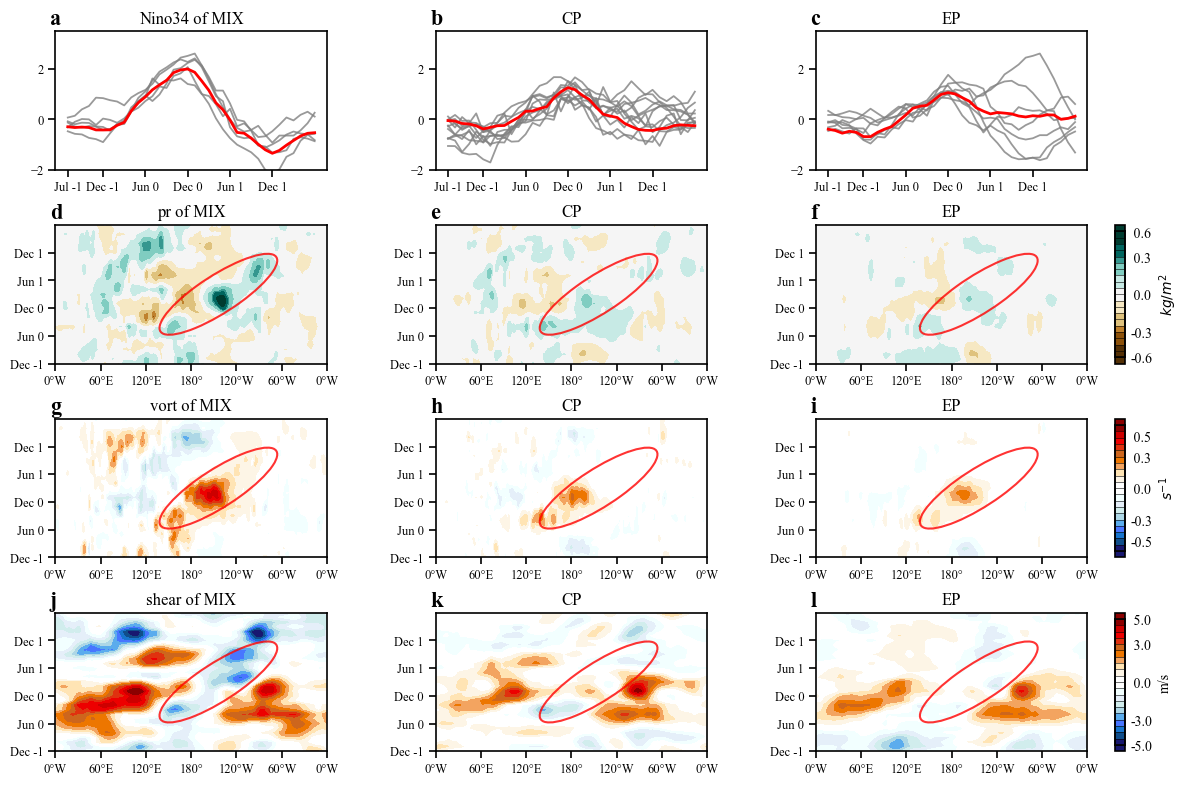

In [10]:
ds_kde = xr.open_dataset('./data-20c/composite_kde.nc')
ds_nino = xr.open_dataset('./data-20c/composite_tc_sst.nc')
nino34 = ds_nino.sst.loc[:, :, -5:5, 190:240].mean(dim=['lat', 'lon'])
vort = ds_kde.vort
# shear = np.sqrt(ds_kde.dudz**2+ds_kde.dvdz**2)
shear = ds_kde.uwnd.loc[:, :, 200] - ds_kde.uwnd.loc[:, :, 850]
apcp = ds_kde.apcp
mon = ds_kde.month.values
vort_grid = combine_data(vort, SH=True)
shear_grid = combine_data(shear)
apcp_grid = combine_data(apcp)

titles = ['Nino34 of MIX', 'CP', 'EP', 'SUC']
texts = alh[:3]
months_str = np.array(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
months_str = np.array([f'{months_str[mon[i]]} -1' for i in range(6)] + [f'{months_str[mon[i]]} 0' for i in range(6, 18)] + [f'{months_str[mon[i]-12]} 1' for i in range(18, 30)] + [f'{months_str[mon[i]-24]} 2' for i in range(30, 36)])
lon = ds_kde.lon.values

level_vort = np.linspace(-0.6, 0.6, 21)
level_shear = np.linspace(-5, 5, 21)
level_apcp = np.linspace(-0.5, 0.5, 21)

fig, axs = plt.subplots(4, 3, figsize=(12, 8))
plot_nino34(nino34, axs[0, :], draw_title=True, draw_lines=True, draw_text=True)

titles = ['pr of MIX', 'CP', 'EP', 'SUC']
texts = alh[3:6]
cb = plot_sst(axs[1, :], apcp_grid.rolling(lon=4, month=3, min_periods=1, center=True).mean(), level_apcp, cmap=cmaps.CBR_drywet, draw_title=True, draw_text=True)
cax = inset_axes(axs[1, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0, 1, 1), bbox_transform=axs[1, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-0.6, -0.3, 0, 0.3, 0.6])
cbar.ax.set_ylabel(r'$kg/m^2$')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

titles = ['vort of MIX', 'CP', 'EP', 'SUC']
texts = alh[6:9]
cb = plot_sst(axs[2, :], vort_grid.rolling(lon=3, month=3, min_periods=1, center=True).mean()*1e+5, level_vort, draw_title=True, draw_text=True)
# cb = plot_sst(axs[1, :], tcg_grid, level_tcg)
cax = inset_axes(axs[2, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0, 1, 1), bbox_transform=axs[2, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-0.5, -0.3, 0, 0.3, 0.5])
cbar.ax.set_ylabel(r'$s^{-1}$')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

titles = ['shear of MIX', 'CP', 'EP', 'SUC']
texts = alh[9:12]

cb = plot_sst(axs[3, :], shear_grid.rolling(lon=3, month=3, min_periods=1, center=True).mean(), level_shear, draw_title=True, draw_text=True)
# cb = plot_sst(axs[1, :], tcg_grid, level_tcg)
cax = inset_axes(axs[3, 2], width="4%", height="100%",  loc='lower left', bbox_to_anchor=(1.1, 0, 1, 1), bbox_transform=axs[3, 2].transAxes, borderpad=0) 
cbar = plt.colorbar(cb, orientation="vertical", drawedges=True, spacing='uniform', extendrect=True, format='%4.1f', cax=cax)
cbar.ax.tick_params(length=0)
cbar.ax.set_yticks([-5, -3, 0, 3, 5])
cbar.ax.set_ylabel('m/s')
for spine in cbar.ax.spines.values():
    spine.set_visible(True)
    spine.set_linewidth(1.2) 
    spine.set_edgecolor('black')

for ax in axs[1:, :].flatten():
    ax.add_patch(Ellipse(xy=(0.6, 0.5), width=0.7, height=0.2, angle=55, linewidth=1.5,
                     edgecolor='red', facecolor='none', alpha=0.8, transform=ax.transAxes))
fig.subplots_adjust(left=0.07, right=0.93, bottom=0.05, top=0.95, wspace=0.4, hspace=0.4) 
fig.savefig('./pic-20c/vort shear month-lon.png')